<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/flexrouter_dpp_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Setup Environment and Core Imports]
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F

# Set deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"FlexRouter Prototype Environment Initialized on Device: {device}")

FlexRouter Prototype Environment Initialized on Device: cuda


In [2]:
# [CELL 2 - Multi-Model Candidate Pool & Quality/Correlation Simulator]

class CandidateModelPool:
    """
    Simulates a pool of N candidate LLMs with distinct competence profiles
    and feature correlations (e.g., overlapping failure modes).
    """
    def __init__(self, num_models: int = 5, feature_dim: int = 16):
        self.num_models = num_models
        self.feature_dim = feature_dim
        # Latent expertise directions for each candidate LLM
        self.model_profiles = torch.randn(num_models, feature_dim).to(device)

    def evaluate_ground_truth_correctness(self, task_features: torch.Tensor) -> torch.Tensor:
        """
        Computes ground-truth binary correctness (0 or 1) for each model on tasks.
        task_features: [batch_size, feature_dim]
        returns: [batch_size, num_models] binary correctness flags
        """
        logits = torch.matmul(task_features, self.model_profiles.T)
        probs = torch.sigmoid(logits)
        correctness = (probs > 0.45).float()
        return correctness

model_pool = CandidateModelPool(num_models=5, feature_dim=16)
print(f"Candidate Model Pool Initialized with {model_pool.num_models} LLMs.")

Candidate Model Pool Initialized with 5 LLMs.


In [3]:
# [CELL 3 - FlexRouter DPP Kernel Network & Failure-Set Loss]

class FlexRouterDPP(nn.Module):
    """
    FlexRouter Architecture:
    1. Quality Head: Predicts scalar model competence q_i(x) > 0.
    2. Similarity Head: Predicts model latent representations to compute cosine similarity S_ij(x).
    3. DPP Kernel Matrix L = diag(q) * S * diag(q).
    """
    def __init__(self, in_dim: int = 16, num_models: int = 5, latent_dim: int = 8):
        super().__init__()
        self.num_models = num_models
        # Predicts competence scores q_i for each model
        self.quality_net = nn.Sequential(
            nn.Linear(in_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_models),
            nn.Softplus() # Ensures strictly positive quality scores
        )
        # Predicts latent embeddings for model output correlation
        self.emb_net = nn.Sequential(
            nn.Linear(in_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_models * latent_dim)
        )
        self.latent_dim = latent_dim

    def build_dpp_kernel(self, x: torch.Tensor) -> torch.Tensor:
        """Constructs DPP Kernel Matrix L(x) of shape [batch_size, num_models, num_models]."""
        batch_size = x.shape[0]
        q = self.quality_net(x) + 1e-4 # [batch_size, num_models]

        embs = self.emb_net(x).view(batch_size, self.num_models, self.latent_dim)
        embs_norm = F.normalize(embs, p=2, dim=-1)

        # Cosine similarity matrix S_ij
        S = torch.bmm(embs_norm, embs_norm.transpose(1, 2)) # [batch_size, num_models, num_models]

        # L_ij = q_i * S_ij * q_j
        Q = torch.diag_embed(q)
        L = torch.bmm(torch.bmm(Q, S), Q)
        return L, q

def flexrouter_coverage_loss(L_kernel: torch.Tensor, correctness: torch.Tensor) -> torch.Tensor:
    """
    Computes Marginalization Loss over Failure Sets:
    Directly maximizes coverage (probability that at least one selected model is correct).
    """
    batch_size, N, _ = L_kernel.shape
    total_loss = 0.0

    # Identify failure sets (models that answered incorrectly)
    for b in range(batch_size):
        fail_indices = (correctness[b] == 0).nonzero(as_tuple=True)[0]

        # Determinant over full set
        I = torch.eye(N, device=device)
        det_full = torch.det(L_kernel[b] + I)

        if len(fail_indices) == 0:
            # All models succeeded
            p_coverage = 1.0 - (1.0 / (det_full + 1e-6))
        else:
            # Marginalize over failure subset L_F
            L_F = L_kernel[b][fail_indices][:, fail_indices]
            det_fail = torch.det(L_F + torch.eye(len(fail_indices), device=device))
            p_failure = det_fail / (det_full + 1e-6)
            p_coverage = 1.0 - p_failure

        p_coverage = torch.clamp(p_coverage, min=1e-6, max=1.0)
        total_loss += -torch.log(p_coverage)

    return total_loss / batch_size

router = FlexRouterDPP(in_dim=16, num_models=5).to(device)
optimizer = torch.optim.AdamW(router.parameters(), lr=2e-3)
print("FlexRouter DPP Neural Module & Coverage Loss Compiled.")

FlexRouter DPP Neural Module & Coverage Loss Compiled.


In [4]:
# [CELL 4 - Training Loop & Greedy Marginal Inference Engine]

def greedy_dpp_subset_selection(L_mat: torch.Tensor, max_subset_size: int = 3) -> List[int]:
    """
    Greedy subset selection based on marginal log-determinant gain:
    Adaptively selects models balancing competence and non-redundancy.
    """
    N = L_mat.shape[0]
    selected = []
    candidates = list(range(N))

    for _ in range(min(max_subset_size, N)):
        best_item = -1
        best_gain = -1e9

        for c in candidates:
            current_set = selected + [c]
            sub_L = L_mat[current_set][:, current_set]
            gain = torch.logdet(sub_L + torch.eye(len(current_set), device=device)).item()
            if gain > best_gain:
                best_gain = gain
                best_item = c

        if best_item != -1:
            selected.append(best_item)
            candidates.remove(best_item)

    return selected

# Training Loop
epochs = 20
loss_history = []

print("\n=========================================================")
print("FLEXROUTER DPP TRAINING & COVERAGE OPTIMIZATION")
print("=========================================================")

for epoch in range(epochs):
    task_feats = torch.randn(64, 16).to(device)
    correctness = model_pool.evaluate_ground_truth_correctness(task_feats)

    L_kernel, _ = router.build_dpp_kernel(task_feats)
    loss = flexrouter_coverage_loss(L_kernel, correctness)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if (epoch + 1) % 4 == 0:
        print(f"Epoch {epoch+1:2d}/{epochs} | Negative Log-Coverage Loss: {loss.item():.4f}")

print("=========================================================")
print("FlexRouter Optimization Completed Successfully.")


FLEXROUTER DPP TRAINING & COVERAGE OPTIMIZATION
Epoch  4/20 | Negative Log-Coverage Loss: 0.9645
Epoch  8/20 | Negative Log-Coverage Loss: 1.3484
Epoch 12/20 | Negative Log-Coverage Loss: 1.0609
Epoch 16/20 | Negative Log-Coverage Loss: 0.5962
Epoch 20/20 | Negative Log-Coverage Loss: 0.7239
FlexRouter Optimization Completed Successfully.



Benchmark Results across 100 Test Instances (Subset Size k=2):
 -> Naive Top-K Independent Router Coverage: 86%
 -> FlexRouter DPP Complementary Coverage:   86%


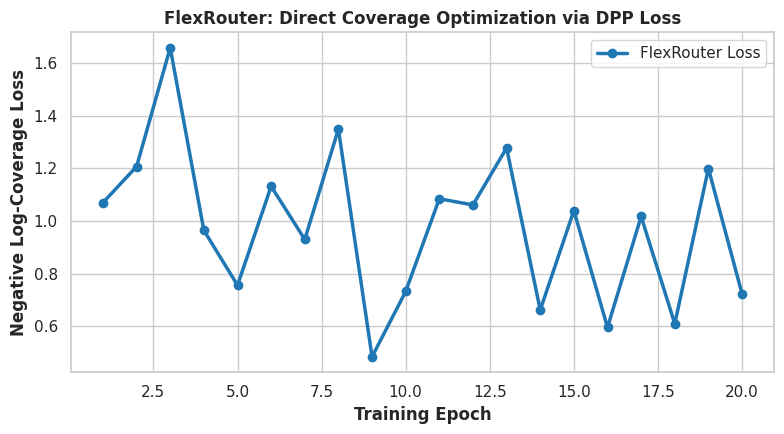

FlexRouter benchmark plot saved successfully as flexrouter_dpp_benchmark.png.


In [5]:
# [CELL 5 - Evaluation & Coverage vs. Redundancy Benchmark Plot]

# Evaluate FlexRouter vs. Naive Independent Top-K Baseline
eval_tasks = torch.randn(100, 16).to(device)
eval_correctness = model_pool.evaluate_ground_truth_correctness(eval_tasks)

flexrouter_coverage = 0
naive_topk_coverage = 0

router.eval()
with torch.no_grad():
    L_kernels, q_scores = router.build_dpp_kernel(eval_tasks)

    for i in range(100):
        # FlexRouter greedy selection (k=2)
        selected_flex = greedy_dpp_subset_selection(L_kernels[i], max_subset_size=2)
        flex_success = (eval_correctness[i][selected_flex].sum() > 0).item()
        if flex_success:
            flexrouter_coverage += 1

        # Naive Top-K selection (ignores correlations)
        topk_naive = torch.topk(q_scores[i], k=2).indices.cpu().tolist()
        naive_success = (eval_correctness[i][topk_naive].sum() > 0).item()
        if naive_success:
            naive_topk_coverage += 1

print(f"\nBenchmark Results across 100 Test Instances (Subset Size k=2):")
print(f" -> Naive Top-K Independent Router Coverage: {naive_topk_coverage}%")
print(f" -> FlexRouter DPP Complementary Coverage:   {flexrouter_coverage}%")

# Visualization
plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

plt.plot(range(1, epochs + 1), loss_history, marker='o', color='#1f77b4', linewidth=2.5, label='FlexRouter Loss')
plt.xlabel('Training Epoch', fontweight='bold')
plt.ylabel('Negative Log-Coverage Loss', fontweight='bold')
plt.title('FlexRouter: Direct Coverage Optimization via DPP Loss', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig("flexrouter_dpp_benchmark.png", dpi=300)
plt.show()

print("FlexRouter benchmark plot saved successfully as flexrouter_dpp_benchmark.png.")